# What is a grid battery worth in Spain?
### Forecast-driven arbitrage in the day-ahead market, a reinforcement-learning comparison and an investment valuation

**AI for Finance — Final Capstone (Type A: free application)** · IE Business School, Master in Finance · Wassim Ibrahim

This notebook reproduces **every table and figure** of the manuscript from public data. Run it top to bottom
(*Runtime → Run all*). It needs no file upload and no API key: the hourly prices are stored in the notebook
(and can be re-downloaded from Red Eléctrica's public API with one function call).

| Step | What it does | Runtime |
|---|---|---|
| 0 | install and import | ~30 s |
| 1 | write the `bess` package (data, battery LP, forecasts, RL, valuation) | 1 s |
| 2 | load 2015–2026 hourly Spanish day-ahead prices | 5 s |
| 3 | the decision problem: one day, one battery, one linear programme | 1 s |
| 4 | walk-forward price forecasts (naive, LEAR, LightGBM, ensemble) — no look-ahead | ~4 min |
| 5 | backtests, reinforcement learning, robustness, valuation; all tables and figures | ~3 min |
| 6 | results, one section per manuscript table and figure | — |

## 0. Setup

In [1]:
# Colab ships pandas, numpy, scipy, scikit-learn, matplotlib and lightgbm. These three may be missing elsewhere.
!pip -q install lightgbm holidays shap
import os, sys, json, lzma, base64, io
os.makedirs("src/bess", exist_ok=True); os.makedirs("data", exist_ok=True); os.makedirs("results/figures", exist_ok=True)
sys.path.insert(0, "src")

## 1. The code
The project is a small Python package, `bess`, identical to the `src/bess` folder of the GitHub repository.
Each cell below writes one module. Read them in this order: `battery` (the physics and the optimiser),
`forecast` (the price models), `backtest`, `rl`, `valuation`, `pipeline` (which runs everything).

In [2]:
%%writefile src/bess/__init__.py
"""Merchant battery storage in the Spanish day-ahead market: forecasting, dispatch, RL and valuation."""
__version__ = "1.0.0"

Writing src/bess/__init__.py


In [3]:
%%writefile src/bess/data.py
"""Data loading: hourly Spanish day-ahead prices (Red Electrica, REData API, series 'Precio mercado spot').

The repository ships a cached CSV (data/ree_spot_prices_2015_2026.csv). If it is missing, `download_ree`
rebuilds it from the public REE API (no key needed). Quarter-hour prices (from late 2025) are averaged to hours.
"""
from __future__ import annotations
import os, json, time, urllib.request
import numpy as np
import pandas as pd

CACHE = os.path.join(os.path.dirname(__file__), "..", "..", "data", "ree_spot_prices_2015_2026.csv")
API = ("https://apidatos.ree.es/es/datos/mercados/precios-mercados-tiempo-real"
       "?start_date={s}T00:00&end_date={e}T23:59&time_trunc=hour")


def download_ree(start="2015-01-01", end="2026-11-25", path=CACHE):
    """Download hourly spot prices month by month from the public REE API and save them as CSV."""
    rows = {}
    for m in pd.period_range(start[:7], end[:7], freq="M"):
        s, e = m.start_time.strftime("%Y-%m-%d"), min(m.end_time, pd.Timestamp(end)).strftime("%Y-%m-%d")
        with urllib.request.urlopen(API.format(s=s, e=e), timeout=60) as r:
            j = json.load(r)
        ser = next((x for x in j["included"] if x["attributes"]["title"] == "Precio mercado spot"), j["included"][0])
        for v in ser["attributes"]["values"]:
            rows[v["datetime"]] = v["value"]
        time.sleep(0.2)
    s = pd.Series(rows)
    t = pd.to_datetime(s.index, utc=True)
    df = pd.DataFrame({"utc": t.floor("h"), "local": [k[:13] + ":00" + k[23:] for k in s.index], "p": s.values})
    out = df.groupby("utc").agg(local_datetime=("local", "first"), price_eur_mwh=("p", "mean"), n_obs=("p", "size")).reset_index()
    out["utc_hour"] = out["utc"].dt.strftime("%Y-%m-%dT%H:%MZ")
    out[["utc_hour", "local_datetime", "price_eur_mwh", "n_obs"]].to_csv(path, index=False, float_format="%.3f")
    return path


def load_hourly(path=CACHE) -> pd.DataFrame:
    if not os.path.exists(path):
        download_ree(path=path)
    d = pd.read_csv(path)
    d["date"] = pd.to_datetime(d["local_datetime"].str[:10])
    d["hour"] = d["local_datetime"].str[11:13].astype(int)
    return d[["date", "hour", "price_eur_mwh"]].rename(columns={"price_eur_mwh": "price"})


def daily_matrix(hourly: pd.DataFrame) -> pd.DataFrame:
    """One row per delivery day, 24 columns (local hours 0-23).

    Daylight-saving days: the missing spring hour is filled by linear interpolation; the repeated autumn
    hour is averaged (standard practice in electricity-price forecasting, Lago et al. 2021)."""
    m = hourly.groupby(["date", "hour"])["price"].mean().unstack("hour")
    m = m.reindex(columns=range(24)).interpolate(axis=1, limit_direction="both")
    m.columns = [f"h{h:02d}" for h in range(24)]
    return m.sort_index()

Writing src/bess/data.py


In [4]:
%%writefile src/bess/battery.py
"""Battery model and optimal daily dispatch (linear programme, solved with HiGHS via scipy).

Decision variables per hour h: grid energy charged c_h >= 0 and discharged d_h >= 0 (MWh).
State of charge: s_{h+1} = s_h + eta_c * c_h - d_h / eta_d, 0 <= s_h <= E, s_0 = s_24 = s_init.
Objective: maximise sum_h p_h (d_h - c_h) - fee * (c_h + d_h) - deg * d_h.
`deg` is the degradation (wear) cost per MWh discharged: replacement cost per MWh of capacity divided by
the cycle life. It stops the optimiser from cycling for spreads that do not pay for the wear they cause.
"""
from __future__ import annotations
from dataclasses import dataclass
import numpy as np
from scipy.optimize import linprog
from scipy.sparse import lil_matrix


@dataclass
class Battery:
    power_mw: float = 1.0          # charge/discharge limit, MW
    energy_mwh: float = 2.0        # usable energy, MWh (2-hour battery)
    rte: float = 0.87              # round-trip efficiency (AC-AC)
    deg_eur_mwh: float = 20.0      # wear cost per MWh discharged
    fee_eur_mwh: float = 0.5       # market/grid fee per MWh traded, each direction
    soc_init_frac: float = 0.0     # state of charge at midnight (start = end)

    @property
    def eta(self):
        return np.sqrt(self.rte)


class DailyLP:
    """Pre-built LP for a 24-hour horizon; only the price vector changes between days."""

    def __init__(self, bat: Battery, T: int = 24):
        self.b, self.T = bat, T
        n = 3 * T + 1                    # c (T), d (T), s (T+1)
        self.n = n
        A = lil_matrix((T + 2, n))
        b = np.zeros(T + 2)
        e = bat.eta
        for h in range(T):               # s_{h+1} - s_h - e*c_h + d_h/e = 0
            A[h, 2 * T + h + 1] = 1
            A[h, 2 * T + h] = -1
            A[h, h] = -e
            A[h, T + h] = 1 / e
        A[T, 2 * T] = 1; b[T] = bat.soc_init_frac * bat.energy_mwh
        A[T + 1, 3 * T] = 1; b[T + 1] = bat.soc_init_frac * bat.energy_mwh
        self.A_eq, self.b_eq = A.tocsr(), b
        self.bounds = [(0, bat.power_mw)] * (2 * T) + [(0, bat.energy_mwh)] * (T + 1)

    def solve(self, price: np.ndarray):
        T, b = self.T, self.b
        cost = np.zeros(self.n)
        cost[:T] = price + b.fee_eur_mwh                    # charging: pay price + fee
        cost[T:2 * T] = -price + b.fee_eur_mwh + b.deg_eur_mwh  # discharging: earn price - fee - wear
        r = linprog(cost, A_eq=self.A_eq, b_eq=self.b_eq, bounds=self.bounds, method="highs")
        x = r.x
        return x[:T], x[T:2 * T]


def settle(c, d, price, bat: Battery):
    """Cash flows of a schedule (c, d) settled at realised prices."""
    revenue = float(np.dot(price, d - c))
    fees = bat.fee_eur_mwh * float(c.sum() + d.sum())
    wear = bat.deg_eur_mwh * float(d.sum())
    return {"gross": revenue - fees, "wear": wear, "net": revenue - fees - wear,
            "mwh_out": float(d.sum()), "cycles": float(d.sum()) / (bat.energy_mwh * bat.eta)}

Writing src/bess/battery.py


In [5]:
%%writefile src/bess/forecast.py
"""Day-ahead price forecasts, produced walk-forward with no look-ahead.

Timing. Bids for delivery day D close at noon of D-1. At that moment the prices of D-1 are known (they were
set at noon of D-2), so every feature uses prices up to D-1 and calendar facts about D. Models are refitted at
the start of each month on all data available then (expanding window) and never see the month they forecast.

Models
- naive_d1:  price(D, h) = price(D-1, h)
- naive_d7:  price(D, h) = price(D-7, h)
- lear:      LASSO-estimated autoregressive model, one model per hour, the standard benchmark of the
             electricity-price-forecasting literature (Lago, Marcjasz, De Schutter and Weron 2021).
             Inputs: the 24 prices of D-1, D-2, D-3 and D-7, day-of-week and holiday dummies; prices are
             transformed with asinh (robust to zero and negative prices); 2-year rolling calibration window.
- lgbm:      gradient-boosted trees (LightGBM) on a long table (one row per day and hour) with lags,
             daily statistics of the last week, hour, weekday, month and holiday flags; expanding window.
"""
from __future__ import annotations
import warnings
import numpy as np
import pandas as pd
import holidays
from sklearn.linear_model import LassoLarsIC
from sklearn.preprocessing import StandardScaler

H = [f"h{h:02d}" for h in range(24)]
# Chosen on the 2017-2018 validation years (grid: leaves 15/31/63, 300 trees at 0.05 or 600 at 0.03).
LGBM_PARAMS = dict(n_estimators=300, learning_rate=0.05, num_leaves=15, min_child_samples=50,
                   subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0)


def es_holidays(index):
    hol = holidays.country_holidays("ES", years=range(index.year.min(), index.year.max() + 1))
    return np.array([d in hol for d in index.date], dtype=float)


def naive(M: pd.DataFrame, lag: int) -> pd.DataFrame:
    return M.shift(lag)


# ---------------------------------------------------------------- LEAR
def _lear_X(Z: pd.DataFrame, index) -> pd.DataFrame:
    parts = [Z.shift(l).add_prefix(f"l{l}_") for l in (1, 2, 3, 7)]
    X = pd.concat(parts, axis=1)
    dow = pd.get_dummies(index.dayofweek, prefix="dow", dtype=float).set_index(index)
    X = pd.concat([X, dow], axis=1)
    X["hol"] = es_holidays(index)
    return X


def lear(M: pd.DataFrame, start: str, window_days: int = 728) -> pd.DataFrame:
    """Variance-stabilised LEAR: prices are centred on the median and scaled by the median absolute deviation
    of the calibration window, then transformed with asinh (Uniejewski, Weron and Ziel 2018)."""
    out = pd.DataFrame(index=M.index[M.index >= start], columns=H, dtype=float)
    for month in pd.period_range(out.index.min(), out.index.max(), freq="M"):
        t0 = month.start_time
        win = M[(M.index < t0) & (M.index >= t0 - pd.Timedelta(days=window_days + 7))]
        med = np.median(win.values); mad = np.median(np.abs(win.values - med)) * 1.4826 + 1e-6
        Z = np.arcsinh((M - med) / mad)
        X = _lear_X(Z, M.index)
        tr = X.index[(X.index < t0) & (X.index >= t0 - pd.Timedelta(days=window_days))]
        tr = tr[X.loc[tr].notna().all(axis=1)]
        te = out.index[(out.index >= t0) & (out.index <= month.end_time)]
        sc = StandardScaler().fit(X.loc[tr])
        Xtr, Xte = sc.transform(X.loc[tr]), sc.transform(X.loc[te])
        for h in H:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                m = LassoLarsIC(criterion="aic").fit(Xtr, Z.loc[tr, h])
            out.loc[te, h] = np.sinh(m.predict(Xte)) * mad + med
    return out


# ---------------------------------------------------------------- LightGBM
def _long_table(M: pd.DataFrame) -> pd.DataFrame:
    d1, d7 = M.shift(1), M.shift(7)
    stats = pd.DataFrame({
        "d1_mean": d1.mean(axis=1), "d1_min": d1.min(axis=1), "d1_max": d1.max(axis=1), "d1_std": d1.std(axis=1),
        "w_mean": M.shift(1).rolling(7).mean().mean(axis=1),
        "d1_solar_dip": d1[["h13", "h14", "h15", "h16"]].mean(axis=1) - d1.mean(axis=1),
        "d1_evening": d1[["h20", "h21", "h22"]].mean(axis=1) - d1.mean(axis=1),
    }, index=M.index)
    hol = es_holidays(M.index)
    rows = []
    for k, h in enumerate(H):
        f = pd.DataFrame(index=M.index)
        f["hour"] = k
        f["p_d1"] = d1[h]; f["p_d2"] = M.shift(2)[h]; f["p_d7"] = d7[h]
        f["p_w"] = M[h].shift(1).rolling(7).mean()
        f["p_d1_rank"] = d1.rank(axis=1, pct=True)[h]
        f = f.join(stats)
        f["dow"] = M.index.dayofweek; f["month"] = M.index.month; f["hol"] = hol
        f["hol_d1"] = np.roll(hol, 1)
        f["y"] = M[h]
        rows.append(f)
    L = pd.concat(rows).sort_index(kind="stable")
    return L


def lgbm(M: pd.DataFrame, start: str, params: dict | None = None, seed: int = 0) -> pd.DataFrame:
    """Walk-forward LightGBM. Default hyperparameters were chosen on the 2017-2018 validation years."""
    import lightgbm as lgb
    params = params or LGBM_PARAMS
    L = _long_table(M)
    feats = [c for c in L.columns if c != "y"]
    out = pd.DataFrame(index=M.index[M.index >= start], columns=H, dtype=float)
    for month in pd.period_range(out.index.min(), out.index.max(), freq="M"):
        t0 = month.start_time
        tr = L[(L.index < t0)].dropna()
        te = L[(L.index >= t0) & (L.index <= month.end_time)]
        m = lgb.LGBMRegressor(objective="l1", random_state=seed, verbose=-1, n_jobs=2, **params)
        m.fit(tr[feats], tr["y"])
        p = m.predict(te[feats])
        for (d, hr), v in zip(zip(te.index, te["hour"]), p):
            out.at[d, H[hr]] = v
    return out


def last_lgbm_model(M: pd.DataFrame, end: str):
    """Model trained on all data before `end` (for interpretation)."""
    import lightgbm as lgb
    L = _long_table(M)
    feats = [c for c in L.columns if c != "y"]
    tr = L[L.index < end].dropna()
    m = lgb.LGBMRegressor(objective="l1", random_state=0, verbose=-1, **LGBM_PARAMS).fit(tr[feats], tr["y"])
    return m, L, feats

Writing src/bess/forecast.py


In [6]:
%%writefile src/bess/backtest.py
"""Backtest: turn a price forecast into a daily schedule and settle it at realised prices."""
from __future__ import annotations
import numpy as np
import pandas as pd
from .battery import Battery, DailyLP, settle


def clock_profile(M: pd.DataFrame, lookback_days: int = 365) -> pd.DataFrame:
    """'Schedule by the clock': for each day, the average hourly profile of the trailing year (known at D-1).
    Re-estimated monthly, so the schedule only changes at month starts."""
    prof = pd.DataFrame(index=M.index, columns=M.columns, dtype=float)
    for month in pd.period_range(M.index.min(), M.index.max(), freq="M"):
        t0 = month.start_time
        hist = M[(M.index < t0) & (M.index >= t0 - pd.Timedelta(days=lookback_days))]
        if len(hist) < 28:
            continue
        sel = (M.index >= t0) & (M.index <= month.end_time)
        prof.loc[sel] = hist.mean().values
    return prof


def run(M: pd.DataFrame, signal: pd.DataFrame, bat: Battery, start: str, end: str | None = None) -> pd.DataFrame:
    """Schedule each day on `signal` (forecast of D, or realised D for perfect foresight); settle at M."""
    lp = DailyLP(bat)
    days = signal.loc[start:end].dropna().index
    rows = []
    for d in days:
        c, dch = lp.solve(signal.loc[d].values.astype(float))
        r = settle(c, dch, M.loc[d].values.astype(float), bat)
        r["date"] = d
        rows.append(r)
    return pd.DataFrame(rows).set_index("date")


def summarise(res: dict, bat: Battery, freq: str = "YE") -> pd.DataFrame:
    """Annual net margin (EUR per MW-year), capture rate vs perfect foresight, cycles per year."""
    out = {}
    for k, r in res.items():
        g = r.resample(freq)
        out[k] = g["net"].sum() / bat.power_mw
    df = pd.DataFrame(out)
    df.index = df.index.year if freq == "YE" else df.index
    return df

Writing src/bess/backtest.py


In [7]:
%%writefile src/bess/rl.py
"""Tabular Q-learning dispatch agent (the reinforcement-learning alternative to predict-then-optimise).

Each hour of the delivery day the agent observes a state and picks charge / idle / discharge at full power.
State (1.800 states): hour of day (24) x state-of-charge bucket (5) x quintile of the hour's *forecast* price
within the forecast day (5) x where that forecast stands among the hours still to come (3). Reward: realised cash flow of the hour (price x energy, minus fee and wear).
It learns on the training days with epsilon-greedy exploration, then trades the test days greedily.
The forecast used in the state is the same walk-forward forecast given to the optimiser, so the comparison
isolates the decision method: learned policy vs. explicit optimisation of the battery model.
"""
from __future__ import annotations
import numpy as np
import pandas as pd
from .battery import Battery

CH, IDLE, DIS = 0, 1, 2


def _quintile(f: np.ndarray) -> np.ndarray:
    r = f.argsort(axis=1).argsort(axis=1)            # rank 0..23 within the day
    return np.minimum(4, (r * 5) // 24)


def _ahead(f: np.ndarray) -> np.ndarray:
    """Where this hour's forecast stands among the hours still to come today (incl. itself):
    0 = among the cheapest third, 1 = middle, 2 = among the dearest third."""
    out = np.zeros(f.shape, dtype=int)
    for h in range(24):
        rest = f[:, h:]
        pct = (rest < f[:, [h]]).sum(axis=1) / max(1, rest.shape[1] - 1) if rest.shape[1] > 1 else np.full(len(f), 0.5)
        out[:, h] = np.minimum(2, (pct * 3).astype(int))
    return out


def _state_feats(fcst: np.ndarray):
    return _quintile(fcst), _ahead(fcst)


def _step(soc, a, price, bat: Battery):
    e = bat.eta
    if a == CH:
        q = min(bat.power_mw, (bat.energy_mwh - soc) / e)        # grid MWh bought
        return soc + e * q, -price * q - bat.fee_eur_mwh * q
    if a == DIS:
        q = min(bat.power_mw, soc * e)                            # grid MWh sold
        return soc - q / e, price * q - (bat.fee_eur_mwh + bat.deg_eur_mwh) * q
    return soc, 0.0


def _soc_bin(soc, bat):
    return min(4, int(soc / bat.energy_mwh * 5 + 1e-9))


def train_q(actual: pd.DataFrame, fcst: pd.DataFrame, bat: Battery, passes=150, gamma=0.995,
            eps_end=0.02, seed=0):
    rng = np.random.default_rng(seed)
    A = actual.values
    F, G = _state_feats(fcst.values)
    Q = np.zeros((24, 5, 5, 3, 3)); N = np.zeros_like(Q)
    nd = len(A)
    for p in range(passes):
        eps = max(eps_end, 1.0 - p / (0.7 * passes))
        for d in rng.permutation(nd):
            soc = 0.0
            scale = 1.0 / (np.abs(A[d]).mean() + 10.0)   # rewards in units of the day's price level: stabler learning
            for h in range(24):
                s = (h, _soc_bin(soc, bat), F[d, h], G[d, h])
                a = rng.integers(3) if rng.random() < eps else int(Q[s].argmax())
                soc2, r = _step(soc, a, A[d, h], bat)
                r *= scale
                if h < 23:
                    tgt = r + gamma * Q[(h + 1, _soc_bin(soc2, bat), F[d, h + 1], G[d, h + 1])].max()
                else:
                    tgt = r
                N[s + (a,)] += 1
                Q[s + (a,)] += (1.0 / N[s + (a,)] ** 0.6) * (tgt - Q[s + (a,)])
                soc = soc2
    return Q


def run_q(Q, actual: pd.DataFrame, fcst: pd.DataFrame, bat: Battery) -> pd.DataFrame:
    A = actual.values
    F, G = _state_feats(fcst.values)
    rows = []
    for d in range(len(A)):
        soc, cash, out = 0.0, 0.0, 0.0
        for h in range(24):
            a = int(Q[(h, _soc_bin(soc, bat), F[d, h], G[d, h])].argmax())
            soc2, r = _step(soc, a, A[d, h], bat)
            if a == DIS:
                out += (soc - soc2) * bat.eta
            soc, cash = soc2, cash + r
        rows.append({"date": actual.index[d], "net": cash, "mwh_out": out,
                     "cycles": out / (bat.energy_mwh * bat.eta)})
    return pd.DataFrame(rows).set_index("date")

Writing src/bess/rl.py


In [8]:
%%writefile src/bess/stats.py
"""Statistical tests."""
import numpy as np
from scipy import stats


def dm_test(a: np.ndarray, b: np.ndarray, lags: int = 7):
    """Diebold-Mariano-type test that the mean of the daily difference a - b is zero, with a Newey-West
    (Bartlett kernel) variance so that serial correlation of daily results does not overstate significance.
    Applied to daily profits (a, b = net EUR per day of two strategies) or to daily losses."""
    d = np.asarray(a, float) - np.asarray(b, float)
    d = d[~np.isnan(d)]
    n, m = len(d), d.mean()
    e = d - m
    v = e @ e / n
    for k in range(1, lags + 1):
        v += 2 * (1 - k / (lags + 1)) * (e[k:] @ e[:-k]) / n
    t = m / np.sqrt(v / n)
    return float(m), float(t), float(2 * (1 - stats.norm.cdf(abs(t))))

Writing src/bess/stats.py


In [9]:
%%writefile src/bess/valuation.py
"""Project valuation of a merchant battery from backtested arbitrage margins (pre-tax, unlevered).

Revenue scenarios are built by bootstrapping calendar months of realised strategy margins (keeps the seasonal
pattern: each simulated January is drawn from the historical Januaries, and so on). Each year's revenue is then
reduced for capacity fade (cell degradation) and for spread compression ('cannibalisation': more storage chasing
the same hours). Assumptions are explicit parameters and every one is varied in the sensitivity tables.
"""
from __future__ import annotations
from dataclasses import dataclass
import numpy as np
import pandas as pd


@dataclass
class Project:
    capex_eur_kwh: float = 200.0     # all-in installed cost per kWh of usable energy
    energy_mwh: float = 2.0
    power_mw: float = 1.0
    opex_frac: float = 0.02          # fixed O&M per year, share of capex (Ember 2025 assumption)
    fade: float = 0.02               # capacity fade per year (Ember 2025 assumption)
    compression: float = 0.03        # yearly fall in arbitrage margin as storage builds out
    life: int = 15
    wacc: float = 0.10               # merchant cost of capital (Ember: 10-15% merchant, 7% contracted)

    @property
    def capex(self):
        return self.capex_eur_kwh * self.energy_mwh * 1000


def simulate_revenue(monthly: pd.Series, years: int, n_sims: int = 5000, seed: int = 0) -> np.ndarray:
    """(n_sims, years) array of annual revenues before fade/compression, bootstrapped by calendar month."""
    rng = np.random.default_rng(seed)
    by_m = {m: monthly[monthly.index.month == m].values for m in range(1, 13)}
    out = np.zeros((n_sims, years))
    for m in range(1, 13):
        v = by_m[m]
        out += v[rng.integers(0, len(v), size=(n_sims, years))]
    return out


def cash_flows(rev: np.ndarray, p: Project) -> np.ndarray:
    t = np.arange(1, rev.shape[1] + 1)
    adj = rev * (1 - p.fade) ** (t - 1) * (1 - p.compression) ** (t - 1)
    return adj - p.opex_frac * p.capex


def npv(cf: np.ndarray, p: Project) -> np.ndarray:
    t = np.arange(1, cf.shape[-1] + 1)
    return -p.capex + (cf / (1 + p.wacc) ** t).sum(axis=-1)


def irr(cf_row: np.ndarray, capex: float) -> float:
    flows = np.concatenate([[-capex], cf_row])
    lo, hi = -0.99, 1.0
    f = lambda r: (flows / (1 + r) ** np.arange(len(flows))).sum()
    if f(lo + 1e-9) * f(hi) > 0:
        return np.nan
    for _ in range(100):
        mid = (lo + hi) / 2
        if f(lo) * f(mid) <= 0:
            hi = mid
        else:
            lo = mid
    return (lo + hi) / 2


def breakeven_capex(rev: np.ndarray, p: Project) -> float:
    """Capex per kWh at which the median-scenario NPV is zero (opex scales with capex)."""
    lo, hi = 1.0, 2000.0
    for _ in range(60):
        mid = (lo + hi) / 2
        q = Project(**{**p.__dict__, "capex_eur_kwh": mid})
        v = np.median(npv(cash_flows(rev, q), q))
        lo, hi = (mid, hi) if v > 0 else (lo, mid)
    return (lo + hi) / 2


def value(rev: np.ndarray, p: Project) -> dict:
    cf = cash_flows(rev, p)
    v = npv(cf, p)
    med_row = cf[np.argsort(v)[len(v) // 2]]
    return {"npv_p10": np.percentile(v, 10), "npv_p50": np.percentile(v, 50), "npv_p90": np.percentile(v, 90),
            "prob_npv_pos": float((v > 0).mean()), "irr_p50": irr(med_row, p.capex),
            "breakeven_capex_eur_kwh": breakeven_capex(rev, p)}

Writing src/bess/valuation.py


In [10]:
%%writefile src/bess/plots.py
"""Figure style shared by every chart (palette: validated categorical order, recessive grid)."""
import matplotlib as mpl
import matplotlib.pyplot as plt

INK, INK2, MUTED, GRID, AXIS, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
C = {"ensemble": "#2a78d6", "lear": "#eb6834", "lgbm": "#1baf7a", "naive_d1": "#eda100", "clock": "#e87ba4",
     "rl": "#6250d6", "perfect": "#52514e", "naive_d7": "#008300"}
LABEL = {"perfect": "Perfect foresight", "ensemble": "Ensemble forecast + LP", "lear": "LEAR forecast + LP",
         "lgbm": "LightGBM forecast + LP", "naive_d1": "Yesterday's prices + LP", "naive_d7": "Last week's prices + LP",
         "clock": "Clock schedule (trailing-year profile)", "rl": "Q-learning agent"}


def style():
    mpl.rcParams.update({
        "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
        "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
        "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
        "axes.spines.top": False, "axes.spines.right": False, "font.size": 9.5, "axes.titlesize": 10.5,
        "axes.titleweight": "bold", "axes.titlelocation": "left", "legend.frameon": False,
        "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "lines.linewidth": 2,
    })


def eu(x, d=0):
    """European number format: 12.345,6"""
    s = f"{x:,.{d}f}"
    return s.replace(",", "X").replace(".", ",").replace("X", ".")

Writing src/bess/plots.py


In [11]:
%%writefile src/bess/pipeline.py
"""End-to-end pipeline: data -> walk-forward forecasts -> dispatch backtests -> RL -> sensitivity -> valuation.

Every table and figure of the manuscript is written to results/ by `run_all()`. Set `use_cache=True` to reuse
saved forecasts (results/forecasts.pkl) and skip the slowest step (about 4 minutes on a laptop).
"""
from __future__ import annotations
import os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from .data import load_hourly, daily_matrix
from .battery import Battery
from . import forecast as F, backtest as B, rl as RL, stats as S, valuation as V
from .plots import style, C, LABEL, INK, INK2, MUTED, eu

ROOT = os.path.abspath(os.path.join(os.path.dirname(__file__), "..", ".."))
RES = os.path.join(ROOT, "results")
FIG = os.path.join(RES, "figures")
TEST_START, END = "2019-01-01", "2026-11-25"
VALID = ("2017-01-01", "2018-12-31")
RL_TRAIN, RL_TEST = ("2021-01-01", "2023-12-31"), ("2024-01-01", END)
BASE = Battery()                      # 1 MW / 2 MWh, RTE 87%, wear 15 EUR/MWh, fee 0,5 EUR/MWh
BASE.deg_eur_mwh = 15.0
STRATS = ["perfect", "ensemble", "lear", "lgbm", "naive_d1", "naive_d7", "clock"]


def _log(msg):
    print(time.strftime("%H:%M:%S"), msg, flush=True)


def build_forecasts(M, use_cache=True):
    path = os.path.join(RES, "forecasts.pkl")
    if use_cache and os.path.exists(path):
        _log("forecasts: loaded from cache")
        return pd.read_pickle(path)
    fc = {"naive_d1": F.naive(M, 1), "naive_d7": F.naive(M, 7)}
    _log("forecasts: LEAR (24 hourly LASSO models, refitted monthly)")
    fc["lear"] = F.lear(M, VALID[0])
    _log("forecasts: LightGBM (refitted monthly)")
    fc["lgbm"] = F.lgbm(M, VALID[0])
    fc["ensemble"] = (fc["lear"] + fc["lgbm"]) / 2
    fc["clock"] = B.clock_profile(M)
    pd.to_pickle(fc, path)
    return fc


def forecast_table(M, fc, start=TEST_START, end=END):
    idx = M.loc[start:end].index
    A = M.loc[idx]
    rows = {}
    base_mae = (fc["naive_d1"].loc[idx] - A).abs().values.mean()
    sp = A.max(axis=1) - A.min(axis=1)
    for k in ["naive_d1", "naive_d7", "lear", "lgbm", "ensemble"]:
        f = fc[k].loc[idx]
        e = (f - A)
        rho = pd.Series([pd.Series(f.loc[d].values).corr(pd.Series(A.loc[d].values), method="spearman")
                         for d in idx]).mean()
        rows[k] = {"MAE": np.abs(e.values).mean(), "RMSE": np.sqrt((e.values ** 2).mean()),
                   "rMAE vs D-1": np.abs(e.values).mean() / base_mae,
                   "Spread MAE": (( f.max(axis=1) - f.min(axis=1)) - sp).abs().mean(),
                   "Rank corr.": rho}
    return pd.DataFrame(rows).T


def backtests(M, fc, bat=BASE, start=TEST_START, end=END, keys=STRATS):
    sig = dict(fc); sig["perfect"] = M
    return {k: B.run(M, sig[k], bat, start, end) for k in keys}


def annual_table(res, bat=BASE):
    S_ = B.summarise(res, bat)
    return S_


def run_all(use_cache=True, n_sims=5000):
    os.makedirs(FIG, exist_ok=True)
    style()
    t0 = time.time()
    M = daily_matrix(load_hourly())
    _log(f"data: {len(M)} days, {M.index.min().date()} to {M.index.max().date()}")
    key = {}

    # ---------- data facts
    yr = M.index.year
    facts = pd.DataFrame({
        "Mean price": M.mean(axis=1).groupby(yr).mean(),
        "Mean daily spread (max-min)": (M.max(axis=1) - M.min(axis=1)).groupby(yr).mean(),
        "Hours at or below 0 (%)": (M <= 0).mean(axis=1).groupby(yr).mean() * 100,
        "Cheapest hour (mode)": M.idxmin(axis=1).str[1:].astype(int).groupby(yr).agg(lambda s: s.mode().iloc[0]),
    })
    facts.to_csv(os.path.join(RES, "t1_market_facts.csv"), float_format="%.2f")

    # ---------- forecasts
    fc = build_forecasts(M, use_cache)
    ft = forecast_table(M, fc); ft.to_csv(os.path.join(RES, "t2_forecast_accuracy_test.csv"), float_format="%.3f")
    fv = forecast_table(M, fc, *VALID); fv.to_csv(os.path.join(RES, "t2b_forecast_accuracy_validation.csv"), float_format="%.3f")
    _log("forecast accuracy computed")

    # ---------- base-case backtests
    res = backtests(M, fc)
    ann = annual_table(res)
    ann.to_csv(os.path.join(RES, "t3_annual_net_margin_eur_per_mw.csv"), float_format="%.0f")
    cap = ann.div(ann["perfect"], axis=0) * 100
    cap.to_csv(os.path.join(RES, "t3b_capture_rate_pct.csv"), float_format="%.1f")
    tot = {k: r["net"].sum() for k, r in res.items()}
    yrs = (pd.Timestamp(END) - pd.Timestamp(TEST_START)).days / 365.25 + 1 / 365.25
    summ = pd.DataFrame({
        "Net margin, test total (EUR/MW)": tot,
        "Capture of perfect foresight (%)": {k: 100 * v / tot["perfect"] for k, v in tot.items()},
        "Cycles per year": {k: r["cycles"].sum() / yrs for k, r in res.items()},
        "Days with a loss (%)": {k: 100 * (r["net"] < -1e-6).mean() for k, r in res.items()},
    })
    summ.to_csv(os.path.join(RES, "t3c_test_summary.csv"), float_format="%.2f")
    # regimes
    reg = {"2019-2020 pre-crisis": ("2019", "2020"), "2021-2022 gas crisis": ("2021", "2022"),
           "2023-2026 solar era": ("2023", "2026")}
    regt = pd.DataFrame({n: {k: 100 * r.loc[a:b, "net"].sum() / res["perfect"].loc[a:b, "net"].sum()
                             for k, r in res.items()} for n, (a, b) in reg.items()})
    regt.to_csv(os.path.join(RES, "t4_capture_by_regime_pct.csv"), float_format="%.1f")
    # DM tests on daily profit: ensemble vs each
    dm = {k: S.dm_test(res["ensemble"]["net"].values, res[k]["net"].values) for k in STRATS if k not in ("ensemble", "perfect")}
    dmt = pd.DataFrame(dm, index=["Mean daily gain (EUR)", "DM statistic", "p-value"]).T
    dmt.to_csv(os.path.join(RES, "t5_dm_tests_ensemble_vs.csv"), float_format="%.4f")
    _log("backtests done")

    # ---------- reinforcement learning (same forecast in the state)
    tr, te = slice(*RL_TRAIN), slice(*RL_TEST)
    Q = RL.train_q(M.loc[tr], fc["ensemble"].loc[tr], BASE, passes=300, gamma=1.0)
    rlres = RL.run_q(Q, M.loc[te], fc["ensemble"].loc[te], BASE)
    rlt = pd.DataFrame({
        "Net margin (EUR/MW)": {"perfect": res["perfect"].loc[te, "net"].sum(), "ensemble": res["ensemble"].loc[te, "net"].sum(),
                                "rl": rlres["net"].sum(), "clock": res["clock"].loc[te, "net"].sum()},
        "Cycles per year": {"perfect": res["perfect"].loc[te, "cycles"].sum(), "ensemble": res["ensemble"].loc[te, "cycles"].sum(),
                            "rl": rlres["cycles"].sum(), "clock": res["clock"].loc[te, "cycles"].sum()}})
    ny = len(rlres) / 365.25
    rlt["Cycles per year"] /= ny
    rlt["Capture (%)"] = 100 * rlt["Net margin (EUR/MW)"] / rlt.loc["perfect", "Net margin (EUR/MW)"]
    rlt.to_csv(os.path.join(RES, "t6_rl_vs_optimisation.csv"), float_format="%.1f")
    _log("RL done")

    # ---------- sensitivity (solar era 2023-2026, perfect vs ensemble)
    sens = []
    for name, kw in [("Base: 2 h, RTE 87%, wear 15", {}), ("Duration 1 h", {"energy_mwh": 1.0}),
                     ("Duration 4 h", {"energy_mwh": 4.0}), ("RTE 80%", {"rte": 0.80}), ("RTE 92%", {"rte": 0.92}),
                     ("Wear 0 EUR/MWh", {"deg_eur_mwh": 0.0}), ("Wear 30 EUR/MWh", {"deg_eur_mwh": 30.0})]:
        b = Battery(**{**BASE.__dict__, **kw})
        r = backtests(M, fc, b, "2023-01-01", END, keys=["perfect", "ensemble"])
        yrs_s = (pd.Timestamp(END) - pd.Timestamp("2023-01-01")).days / 365.25
        sens.append({"Case": name, "Perfect (EUR/MW-yr)": r["perfect"]["net"].sum() / yrs_s,
                     "Ensemble (EUR/MW-yr)": r["ensemble"]["net"].sum() / yrs_s,
                     "Capture (%)": 100 * r["ensemble"]["net"].sum() / r["perfect"]["net"].sum(),
                     "Ensemble cycles/yr": r["ensemble"]["cycles"].sum() / yrs_s,
                     "Ensemble per MWh of capacity (EUR/yr)": r["ensemble"]["net"].sum() / yrs_s / b.energy_mwh})
    sens = pd.DataFrame(sens).set_index("Case"); sens.to_csv(os.path.join(RES, "t7_sensitivity_2023_2026.csv"), float_format="%.1f")
    _log("sensitivity done")

    # ---------- valuation (gross margin: wear is a dispatch shadow price; in the valuation degradation is
    # captured by the capex, the 15-year life and the yearly capacity fade, so it must not be charged twice)
    vrows, revs = [], {}
    for win, (a, b) in {"2023-26": ("2023-01-01", "2026-10-31"), "2025-26": ("2025-01-01", "2026-10-31")}.items():
        monthly = res["ensemble"]["gross"].loc[a:b].resample("ME").sum()
        revs[win] = V.simulate_revenue(monthly, 15, n_sims=n_sims)
        for capex in (120, 160, 200, 280):
            for comp in (0.0, 0.03, 0.06):
                p = V.Project(capex_eur_kwh=capex, compression=comp)
                v = V.value(revs[win], p)
                v.update({"Revenue window": win, "Capex (EUR/kWh)": capex, "Margin compression (%/yr)": comp * 100,
                          "Year-1 revenue P50 (EUR/MW)": float(np.median(revs[win][:, 0]))})
                vrows.append(v)
    vt = pd.DataFrame(vrows); vt.to_csv(os.path.join(RES, "t8_valuation.csv"), float_format="%.4f", index=False)
    rev = revs["2023-26"]
    base_p = V.Project()
    npv_base = V.npv(V.cash_flows(rev, base_p), base_p)
    _log("valuation done")

    # ---------- interpretation: SHAP on the final LightGBM model
    shap_imp = None
    try:
        import shap
        m, L, feats = F.last_lgbm_model(M, "2026-01-01")
        Xs = L.loc["2026-01-01":END, feats].dropna().sample(3000, random_state=0)
        sv = shap.TreeExplainer(m).shap_values(Xs)
        shap_imp = pd.Series(np.abs(sv).mean(axis=0), index=feats).sort_values(ascending=False)
        shap_imp.to_csv(os.path.join(RES, "t9_shap_importance_lgbm.csv"), float_format="%.3f")
    except Exception as e:
        _log(f"SHAP skipped: {e}")

    # ---------- figures
    _figures(M, fc, res, ann, cap, rlres, rev, npv_base, vt, shap_imp)

    # ---------- key numbers
    e, p = res["ensemble"], res["perfect"]
    key.update({
        "test_period": f"{TEST_START} to {END}", "days_test": int(len(e)),
        "ann_perfect": ann["perfect"].round(0).to_dict(), "ann_ensemble": ann["ensemble"].round(0).to_dict(),
        "capture_total": summ["Capture of perfect foresight (%)"].round(1).to_dict(),
        "forecast_mae": ft["MAE"].round(2).to_dict(), "rank_corr": ft["Rank corr."].round(3).to_dict(),
        "regime_capture": regt.round(1).to_dict(), "dm": dmt.round(4).to_dict(),
        "rl": rlt.round(1).to_dict(), "sens": sens.round(1).to_dict(),
        "valuation_base": V.value(rev, base_p), "valuation_2025_26": V.value(revs["2025-26"], base_p),
        "npv_base_mean": float(npv_base.mean()),
        "revenue_year1_p50": float(np.median(rev[:, 0])), "revenue_year1_p10": float(np.percentile(rev[:, 0], 10)),
        "revenue_year1_p90": float(np.percentile(rev[:, 0], 90)),
        "runtime_s": round(time.time() - t0),
    })
    with open(os.path.join(RES, "key_numbers.json"), "w") as f:
        json.dump(key, f, indent=1, default=float)
    _demo_data(M, fc, res)
    _log(f"all done in {time.time() - t0:.0f} s")
    return key


def _figures(M, fc, res, ann, cap, rlres, rev, npv_base, vt, shap_imp):
    # F1 average daily price shape by year
    fig, ax = plt.subplots(figsize=(7.2, 3.4))
    years = [2016, 2019, 2022, 2024, 2026]
    shades = ["#cde2fb", "#9ec5f4", "#5598e7", "#256abf", "#0d366b"]
    for y, c in zip(years, shades):
        prof = M[M.index.year == y].mean()
        ax.plot(range(24), prof.values, color=c, lw=2, label=str(y))
    ax.set_xticks(range(0, 24, 3)); ax.set_xlabel("hour of the day"); ax.set_ylabel("EUR/MWh")
    ax.set_title("Average day-ahead price by hour: the solar 'duck' deepens")
    ax.legend(ncol=5, loc="upper left", fontsize=8.5)
    fig.savefig(os.path.join(FIG, "f1_price_shape.png")); plt.close(fig)

    # F2 annual net margin by strategy
    fig, ax = plt.subplots(figsize=(7.2, 3.6))
    ks = ["clock", "naive_d1", "lear", "lgbm", "ensemble"]
    yrs = ann.index.values; w = 0.16
    for i, k in enumerate(ks):
        ax.bar(yrs + (i - 2) * w, ann[k].values / 1000, width=w - 0.02, color=C[k], label=LABEL[k])
    ax.plot(yrs, ann["perfect"].values / 1000, color=INK, marker="o", ms=4, lw=1.5, label=LABEL["perfect"])
    ax.axhline(0, color=MUTED, lw=0.8)
    ax.set_ylabel("thousand EUR per MW-year"); ax.set_title("Net arbitrage margin of a 1 MW / 2 MWh battery (2026 to 25 Nov)")
    ax.legend(fontsize=7.5, ncol=2, loc="upper left")
    fig.savefig(os.path.join(FIG, "f2_annual_margin.png")); plt.close(fig)

    # F3 capture rate by year
    fig, ax = plt.subplots(figsize=(7.2, 3.0))
    for k in ["clock", "naive_d1", "ensemble"]:
        ax.plot(cap.index, cap[k], color=C[k], marker="o", ms=4, label=LABEL[k])
    ax.axhline(100, color=INK2, lw=1, ls="--"); ax.text(cap.index.min(), 101.5, "perfect foresight = 100%", color=INK2, fontsize=8)
    ax.set_ylim(min(-60, cap[["clock", "naive_d1", "ensemble"]].min().min() - 5), 110)
    ax.set_ylabel("% of perfect-foresight margin"); ax.set_title("Capture rate: forecasting matters most when spreads are thin")
    ax.legend(fontsize=8, loc="lower right")
    fig.savefig(os.path.join(FIG, "f3_capture.png")); plt.close(fig)

    # F4 dispatch heat map (ensemble): average net discharge by hour and year
    from .battery import DailyLP
    lp = DailyLP(BASE)
    rows = []
    for d in M.loc[TEST_START:END].index[::3]:
        c, dch = lp.solve(fc["ensemble"].loc[d].values.astype(float))
        rows.append(pd.Series(dch - c, index=range(24), name=d))
    D = pd.DataFrame(rows); D = D.groupby(D.index.year).mean()
    fig, ax = plt.subplots(figsize=(7.2, 3.0))
    im = ax.imshow(D.values, aspect="auto", cmap="RdBu", vmin=-0.6, vmax=0.6)
    ax.set_yticks(range(len(D))); ax.set_yticklabels(D.index); ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("hour of the day")
    ax.grid(False); ax.set_title("Where the battery buys (red) and sells (blue): average MW by hour")
    cb = fig.colorbar(im, ax=ax, fraction=0.03); cb.set_label("net discharge, MW", color=INK2)
    fig.savefig(os.path.join(FIG, "f4_dispatch_heatmap.png")); plt.close(fig)

    # F5 example week: forecast vs actual and state of charge
    wk = M.loc["2026-04-13":"2026-04-19"]
    fwk = fc["ensemble"].loc[wk.index]
    lp = DailyLP(BASE)
    soc, flow = [], []
    for d in wk.index:
        c, dch = lp.solve(fwk.loc[d].values.astype(float))
        s = np.concatenate([[0], np.cumsum(BASE.eta * c - dch / BASE.eta)])[:-1]
        soc += list(s); flow += list(dch - c)
    x = np.arange(len(soc))
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(7.2, 4.0), sharex=True, gridspec_kw={"height_ratios": [1.6, 1]})
    a1.plot(x, wk.values.ravel(), color=INK2, lw=1.6, label="realised price")
    a1.plot(x, fwk.values.ravel(), color=C["ensemble"], lw=1.6, ls="--", label="forecast at D-1 noon")
    a1.set_ylabel("EUR/MWh"); a1.legend(fontsize=8, loc="upper left", ncol=2)
    a1.set_title("One week of April 2026: forecast, prices and the battery's state of charge")
    a2.fill_between(x, soc, step="post", color=C["ensemble"], alpha=0.35, lw=0)
    a2.step(x, soc, where="post", color=C["ensemble"], lw=1.2)
    a2.set_ylabel("MWh stored"); a2.set_xticks(range(0, len(x), 24)); a2.set_xticklabels([d.strftime("%a %d") for d in wk.index])
    fig.savefig(os.path.join(FIG, "f5_example_week.png")); plt.close(fig)

    # F6 valuation: NPV distribution (base) and NPV vs capex
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.2, 3.0))
    a1.hist(npv_base / 1000, bins=50, color=C["ensemble"], edgecolor="#fcfcfb", linewidth=0.5)
    a1.axvline(0, color=INK, lw=1); a1.set_xlabel("NPV, thousand EUR per MW"); a1.set_ylabel("scenarios")
    a1.set_title("Base case NPV (capex 200 EUR/kWh)")
    caps = np.arange(80, 321, 20)
    for comp, ls in ((0.0, "-"), (0.03, "--"), (0.06, ":")):
        med = [np.median(V.npv(V.cash_flows(rev, q := V.Project(capex_eur_kwh=c_, compression=comp)), q)) / 1000 for c_ in caps]
        a2.plot(caps, med, color=C["ensemble"], ls=ls, lw=1.8, label=f"compression {int(comp*100)}%/yr")
    a2.axhline(0, color=INK, lw=1); a2.set_xlabel("capex, EUR per kWh"); a2.set_ylabel("median NPV, k EUR/MW")
    a2.set_title("Value falls with capex and cannibalisation"); a2.legend(fontsize=7.5)
    fig.tight_layout(); fig.savefig(os.path.join(FIG, "f6_valuation.png")); plt.close(fig)

    # F7 SHAP importance
    if shap_imp is not None:
        names = {"p_d1": "price, same hour, D-1", "d1_evening": "evening premium, D-1", "p_w": "7-day mean, same hour",
                 "p_d7": "price, same hour, D-7", "d1_mean": "daily mean, D-1", "d1_max": "daily max, D-1",
                 "d1_solar_dip": "solar dip, D-1", "dow": "day of week", "d1_min": "daily min, D-1",
                 "d1_std": "daily st. dev., D-1", "w_mean": "7-day mean, all hours", "hour": "hour of day",
                 "month": "month", "p_d2": "price, same hour, D-2", "p_d1_rank": "rank of hour, D-1",
                 "hol": "holiday", "hol_d1": "holiday D-1"}
        top = shap_imp.head(10)[::-1].rename(index=names)
        fig, ax = plt.subplots(figsize=(7.2, 3.0))
        ax.barh(top.index, top.values, color=C["lgbm"], height=0.6)
        ax.set_xlabel("mean |SHAP value|, EUR/MWh"); ax.set_title("What the LightGBM forecast relies on (2026 test days)")
        fig.savefig(os.path.join(FIG, "f7_shap.png")); plt.close(fig)

    # F8 error analysis (solar era): forecasts shrink spreads, and a few days carry most of the lost value
    e, p = res["ensemble"].loc["2023":], res["perfect"].loc["2023":]
    A = M.loc[e.index]; Fc = fc["ensemble"].loc[e.index]
    sp_err = (Fc.max(axis=1) - Fc.min(axis=1)) - (A.max(axis=1) - A.min(axis=1))
    lost = (p["net"] - e["net"]).sort_values(ascending=False)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.2, 3.0))
    a1.hist(sp_err.clip(-150, 150), bins=60, color=C["ensemble"], edgecolor="#fcfcfb", linewidth=0.4)
    a1.axvline(0, color=INK, lw=1); a1.axvline(sp_err.mean(), color=C["lear"], lw=1.5, ls="--")
    a1.set_xlabel("forecast minus realised daily spread, EUR/MWh"); a1.set_ylabel("days")
    a1.set_title("Forecasts shrink the spread")
    a1.text(0.02, 0.95, f"mean {eu(sp_err.mean(), 1)}\nunder-forecast on {eu(100 * (sp_err < 0).mean(), 0)}% of days",
            transform=a1.transAxes, va="top", fontsize=8, color=INK2)
    share_days = np.arange(1, len(lost) + 1) / len(lost) * 100
    share_lost = lost.cumsum().values / lost.sum() * 100
    a2.plot(share_days, share_lost, color=C["ensemble"])
    a2.plot([0, 100], [0, 100], color=MUTED, lw=1, ls=":")
    a2.set_xlabel("% of days, worst first"); a2.set_ylabel("% of value lost vs perfect")
    a2.set_title("A few days carry the loss")
    i10 = int(len(lost) * 0.1)
    a2.annotate(f"worst 10% of days:\n{eu(share_lost[i10 - 1], 0)}% of the loss", (10, share_lost[i10 - 1]),
                (30, 25), fontsize=8, color=INK2, arrowprops=dict(arrowstyle="-", color=MUTED))
    fig.tight_layout(); fig.savefig(os.path.join(FIG, "f8_error_analysis.png")); plt.close(fig)
    pd.Series({"mean_spread_error": sp_err.mean(), "share_days_underforecast": (sp_err < 0).mean(),
               "worst10pct_share_of_loss": share_lost[i10 - 1] / 100}).to_csv(os.path.join(RES, "t10_error_analysis.csv"))


def _demo_data(M, fc, res):
    """Compact JSON for the interactive demo: daily prices + forecast (2023-2026) and annual results."""
    sub = M.loc["2023-01-01":END]
    out = {"dates": [d.strftime("%Y-%m-%d") for d in sub.index],
           "price": np.round(sub.values, 1).tolist(),
           "fcst": np.round(fc["ensemble"].loc[sub.index].values, 1).tolist()}
    with open(os.path.join(RES, "demo_prices.json"), "w") as f:
        json.dump(out, f, separators=(",", ":"))

Writing src/bess/pipeline.py


## 2. Data
Hourly prices of the Spanish day-ahead market (Red Eléctrica de España, REData API, series *Precio mercado spot*),
1 January 2015 to 25 November 2026, downloaded on 24 November 2026. From October 2025 the market clears in
quarter-hours; those are averaged to hours. A compressed copy is stored in the next cell so the notebook runs
offline; `bess.data.download_ree()` rebuilds the file from the API.

In [12]:
#@title Data copy (run it; nothing to read)
PRICES_XZ = (
    "..."
)
if not os.path.exists('data/ree_spot_prices_2015_2026.csv'):
    open('data/ree_spot_prices_2015_2026.csv', 'wb').write(lzma.decompress(base64.b64decode(PRICES_XZ)))
print('data file ready')

data file ready


In [13]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
from bess.data import load_hourly, daily_matrix
from bess.plots import style; style()
M = daily_matrix(load_hourly())
print(f"{len(M):,} delivery days, {M.index.min().date()} to {M.index.max().date()}, {M.size:,} hourly prices")
M.tail(3).round(1)

4,347 delivery days, 2015-01-01 to 2026-11-25, 104,328 hourly prices


,h00,h01,h02,h03,h04,h05,h06,h07,h08,h09,...,h14,h15,h16,h17,h18,h19,h20,h21,h22,h23
date,,,,,,,,,,,,,,,,,,,,,
2026-11-23,187.2,183.2,182.5,181.7,182.4,188.4,210.3,261.2,264.9,189.9,...,146.1,162.7,198.6,237.7,301.1,292.5,280.8,254.6,238.3,213.6
2026-11-24,210.4,210.0,202.7,200.0,200.1,205.8,228.0,238.2,228.0,215.5,...,196.1,196.1,196.8,219.0,223.1,225.3,226.0,220.0,199.6,175.5
2026-11-25,122.1,90.8,62.0,63.2,61.0,61.0,66.8,141.7,170.9,129.6,...,7.4,47.9,107.1,179.2,206.6,215.9,233.6,227.5,206.4,188.0


## 3. The decision problem on one day
At noon of day D−1 the battery submits its 24 hourly buy/sell quantities for day D. It knows the prices of D−1
(set the day before) but not those of D. Given *some* price vector, the best schedule solves a linear programme:
maximise revenue minus fees minus wear, subject to the power limit (1 MW), the energy limit (2 MWh), round-trip
efficiency (87%) and an empty battery at midnight. Below: the schedule computed with the realised prices of one
day (perfect foresight) and with the forecast available at D−1 noon.

In [14]:
from bess.battery import Battery, DailyLP, settle
bat = Battery(deg_eur_mwh=15.0); lp = DailyLP(bat)
day = pd.Timestamp("2026-04-15")
c, d = lp.solve(M.loc[day].values)
pd.DataFrame({"price": M.loc[day].values.round(1), "charge MW": c.round(2), "discharge MW": d.round(2)},
             index=range(24)).T

,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
price,103.7,91.6,84.1,74.5,74.50,77.4,92.7,117.6,100.0,47.8,...,-0.50,-0.8,-0.5,-0.0,5.1,76.2,128.70,134.6,121.2,108.6
charge MW,-0.0,0.0,0.0,1.0,0.15,0.0,0.0,0.0,0.0,0.0,...,0.14,1.0,1.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0
discharge MW,0.0,0.0,0.0,0.0,0.00,0.0,0.0,1.0,-0.0,-0.0,...,0.00,0.0,0.0,0.0,0.0,-0.0,0.87,1.0,0.0,-0.0


In [15]:
print("Perfect foresight on", day.date(), settle(c, d, M.loc[day].values, bat))

Perfect foresight on 2026-04-15 {'gross': 276.3015059420412, 'wear': 42.98213715926644, 'net': 233.31936878277477, 'mwh_out': 2.865475810617763, 'cycles': np.float64(1.5360562674188976)}


## 4. Walk-forward forecasts (no look-ahead)
Four forecasts of the 24 prices of day D, each made with information available at noon of D−1:
yesterday's prices, last week's prices, **LEAR** (24 LASSO regressions on asinh-transformed lags — the standard
benchmark of the electricity-price-forecasting literature) and **LightGBM** (gradient-boosted trees on lags,
daily statistics and calendar). Every model is refitted at the start of each month on data before that month
only. Hyperparameters were chosen on 2017–2018 (validation); 2019–2026 is the untouched test period.
Set `USE_CACHE = True` to reuse forecasts already computed in this runtime.

In [16]:
from bess.pipeline import build_forecasts, forecast_table, VALID
USE_CACHE = False
fc = build_forecasts(M, use_cache=USE_CACHE)
print("Validation 2017-2018 (used to choose hyperparameters):")
display(forecast_table(M, fc, *VALID).round(3))
print("Test 2019 - 25 Nov 2026:")
forecast_table(M, fc).round(3)

22:01:26 forecasts: LEAR (24 hourly LASSO models, refitted monthly)


22:02:28 forecasts: LightGBM (refitted monthly)


Validation 2017-2018 (used to choose hyperparameters):


,MAE,RMSE,rMAE vs D-1,Spread MAE,Rank corr.
naive_d1,5.368,7.983,1.000,5.652,0.664
naive_d7,6.795,10.016,1.266,6.381,0.719
lear,3.718,5.280,0.693,4.480,0.817
lgbm,4.322,6.158,0.805,5.132,0.792
ensemble,3.758,5.374,0.700,4.528,0.824


Test 2019 - 25 Nov 2026:


,MAE,RMSE,rMAE vs D-1,Spread MAE,Rank corr.
naive_d1,16.932,28.143,1.000,20.973,0.740
naive_d7,24.396,39.224,1.441,24.023,0.771
lear,14.511,22.938,0.857,20.850,0.824
lgbm,15.193,24.636,0.897,21.979,0.814
ensemble,13.795,22.008,0.815,19.825,0.838


## 5. Backtests, reinforcement learning, robustness and valuation
This cell writes every table to `results/` and every figure to `results/figures/`.

In [17]:
from bess.pipeline import run_all
key = run_all(use_cache=True)

22:04:24 data: 4347 days, 2015-01-01 to 2026-11-25


22:04:24 forecasts: loaded from cache


22:04:34 forecast accuracy computed


22:05:25 backtests done


22:06:05 RL done


22:06:55 sensitivity done


22:06:56 valuation done


/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


22:07:02 all done in 158 s


## 6. Results
### 6.1 The market: the solar 'duck' and the spread it creates

,Mean price,Mean daily spread (max-min),Hours at or below 0 (%),Cheapest hour (mode)
date,,,,
2015,50.3,25.0,0.0,4
2016,39.7,19.2,0.0,4
2017,52.2,19.5,0.0,4
2018,57.3,18.4,0.0,4
2019,47.7,16.9,0.0,4
2020,34.0,16.9,0.0,4
2021,111.9,49.6,0.0,4
2022,167.5,94.4,0.0,15
2023,87.1,73.3,1.2,15


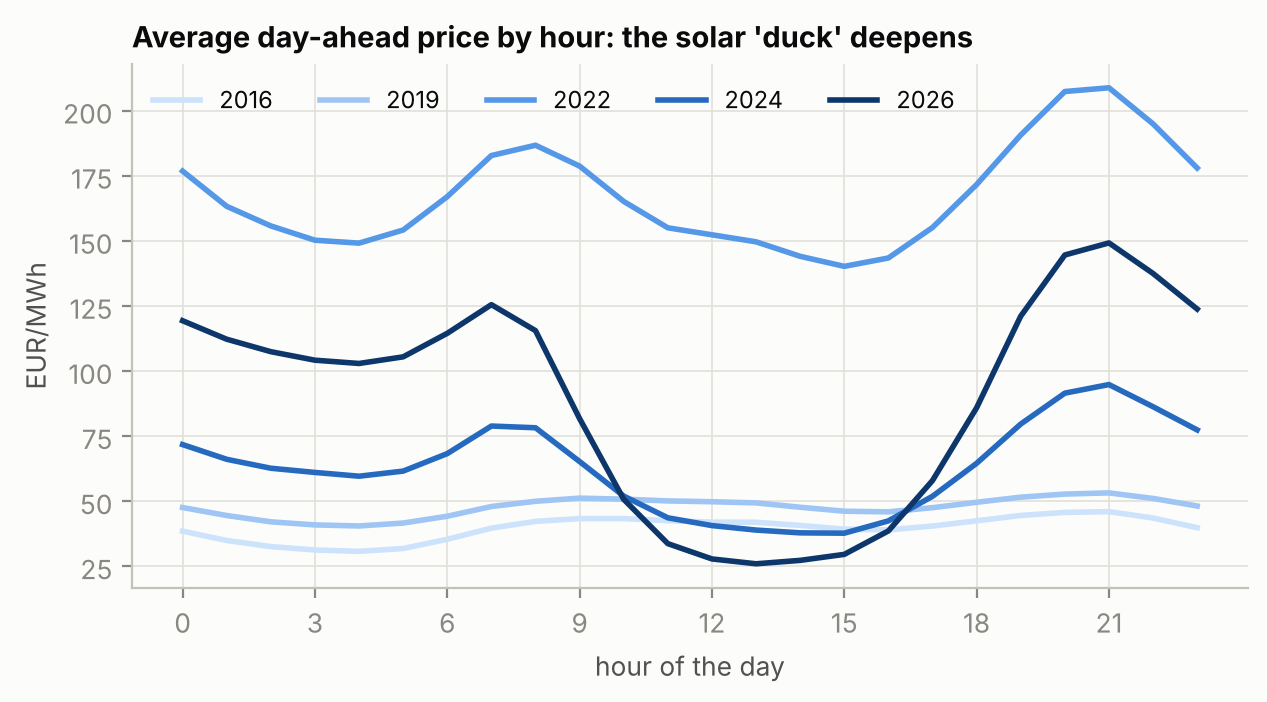

In [18]:
display(pd.read_csv("results/t1_market_facts.csv", index_col=0).round(1)); display(Image("results/figures/f1_price_shape.png", width=720))

### 6.2 Economic value of each strategy (EUR per MW per year, net of fees and wear)

,perfect,ensemble,lear,lgbm,naive_d1,naive_d7,clock
date,,,,,,,
2019,1097,514,460,189,-500,-617,0
2020,941,442,193,228,-509,-573,0
2021,15177,7431,6398,6071,5987,7147,1809
2022,40172,28582,27669,25425,24433,24224,14822
2023,33407,27145,26580,25669,23310,23209,22105
2024,34445,28901,28145,27723,26094,23809,22857
2025,54388,49149,48602,48081,45254,45774,40979
2026,71969,67038,66996,65590,63423,63752,61546


,"Net margin, test total (EUR/MW)",Capture of perfect foresight (%),Cycles per year,Days with a loss (%)
perfect,251595.0,100.0,349.8,0.0
ensemble,209203.6,83.2,316.0,7.6
lear,205042.2,81.5,359.3,11.5
lgbm,198975.6,79.1,284.7,6.4
naive_d1,187492.2,74.5,349.5,13.9
naive_d7,186725.2,74.2,348.5,14.7
clock,164118.9,65.2,231.6,8.4


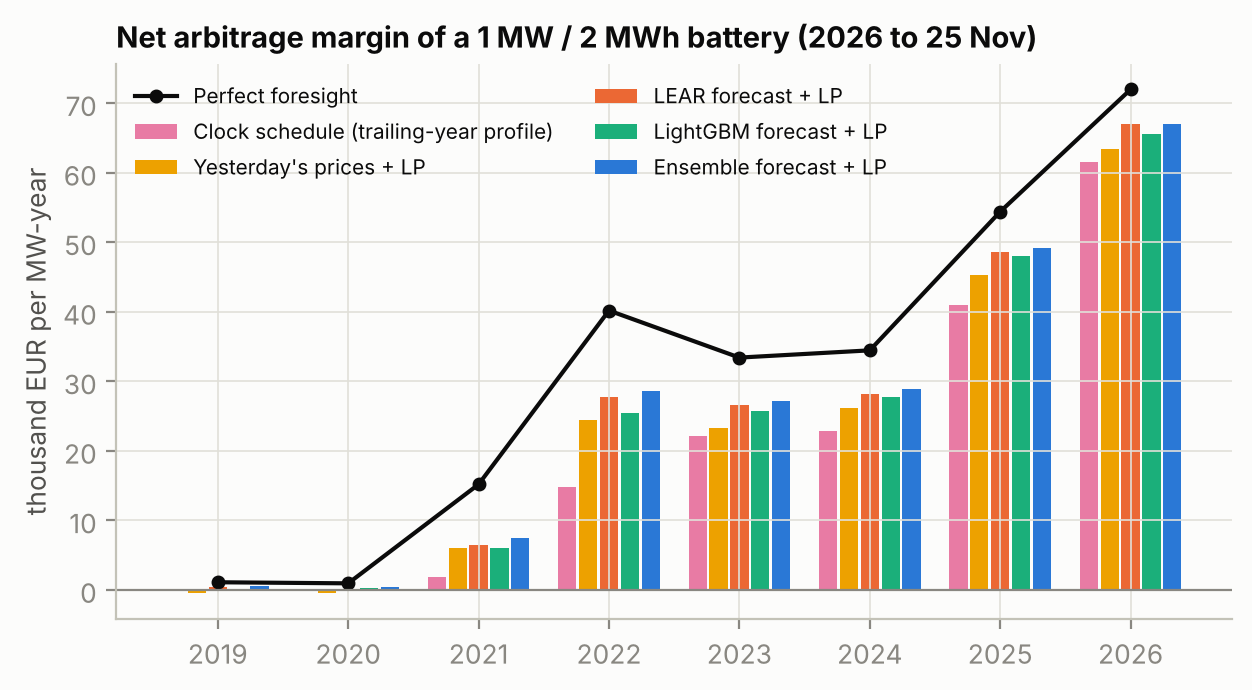

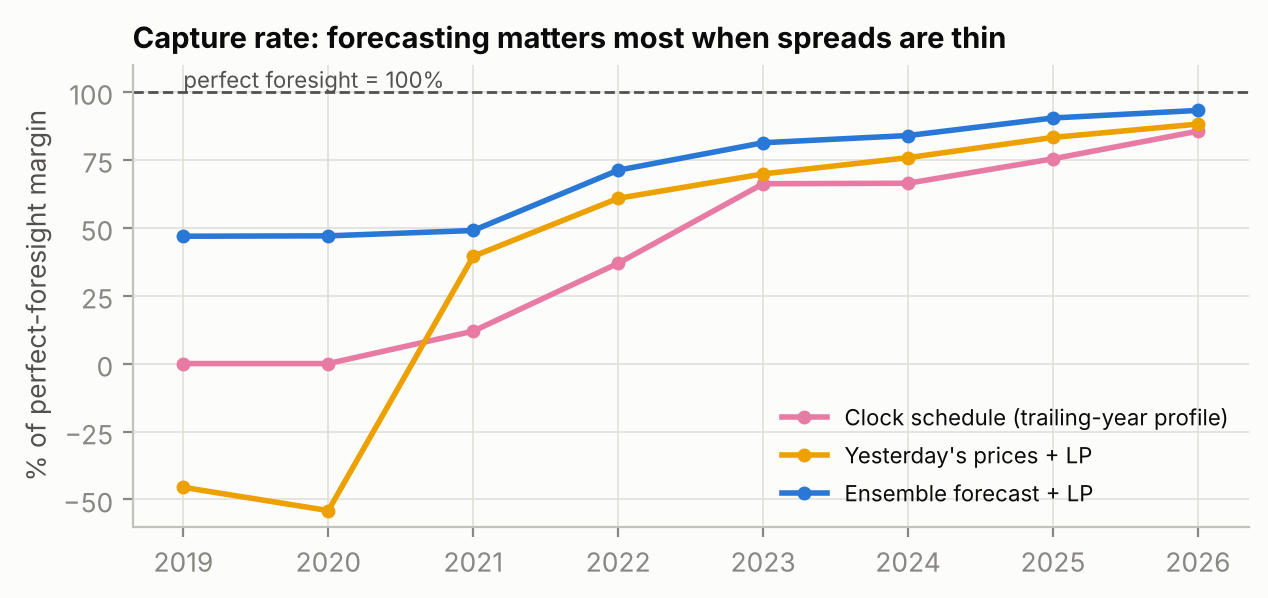

In [19]:
display(pd.read_csv("results/t3_annual_net_margin_eur_per_mw.csv", index_col=0))
display(pd.read_csv("results/t3c_test_summary.csv", index_col=0).round(1))
display(Image("results/figures/f2_annual_margin.png", width=720)); display(Image("results/figures/f3_capture.png", width=720))

### 6.3 Is the gain significant? Diebold–Mariano tests on daily profits (ensemble minus alternative, Newey–West variance)

In [20]:
pd.read_csv("results/t5_dm_tests_ensemble_vs.csv", index_col=0).round(4)

,Mean daily gain (EUR),DM statistic,p-value
lear,1.4419,3.7706,0.0002
lgbm,3.5440,6.4294,0.0000
naive_d1,7.5230,12.9574,0.0000
naive_d7,7.7888,11.0704,0.0000
clock,15.6219,13.6487,0.0000


### 6.4 Robustness across market regimes (capture of perfect foresight, %)

In [21]:
pd.read_csv("results/t4_capture_by_regime_pct.csv", index_col=0).round(1)

,2019-2020 pre-crisis,2021-2022 gas crisis,2023-2026 solar era
perfect,100.0,100.0,100.0
ensemble,46.9,65.1,88.7
lear,32.0,61.5,87.7
lgbm,20.4,56.9,86.0
naive_d1,-49.5,55.0,81.4
naive_d7,-58.4,56.7,80.6
clock,0.0,30.0,75.9


### 6.5 Reinforcement learning versus optimisation (train 2021–2023, test 2024–Nov 2026, same forecast in both)

In [22]:
pd.read_csv("results/t6_rl_vs_optimisation.csv", index_col=0).round(1)

,Net margin (EUR/MW),Cycles per year,Capture (%)
perfect,160801.9,473.4,100.0
ensemble,145088.2,468.8,90.2
rl,124034.8,359.3,77.1
clock,125382.6,365.2,78.0


### 6.6 Sensitivity to the battery's design (2023–2026)

In [23]:
pd.read_csv("results/t7_sensitivity_2023_2026.csv", index_col=0).round(1)

,Perfect (EUR/MW-yr),Ensemble (EUR/MW-yr),Capture (%),Ensemble cycles/yr,Ensemble per MWh of capacity (EUR/yr)
Case,,,,,
"Base: 2 h, RTE 87%, wear 15",49813.7,44177.2,88.7,461.6,22088.6
Duration 1 h,27066.2,23603.0,87.2,492.6,23603.0
Duration 4 h,83035.1,74963.7,90.3,407.9,18740.9
RTE 80%,44524.1,38777.5,87.1,407.5,19388.7
RTE 92%,53824.8,48235.7,89.6,510.9,24117.8
Wear 0 EUR/MWh,64644.1,59564.0,92.1,673.6,29782.0
Wear 30 EUR/MWh,37916.8,31943.4,84.2,350.4,15971.7


### 6.7 Interpretation: what the forecast uses and how the battery trades

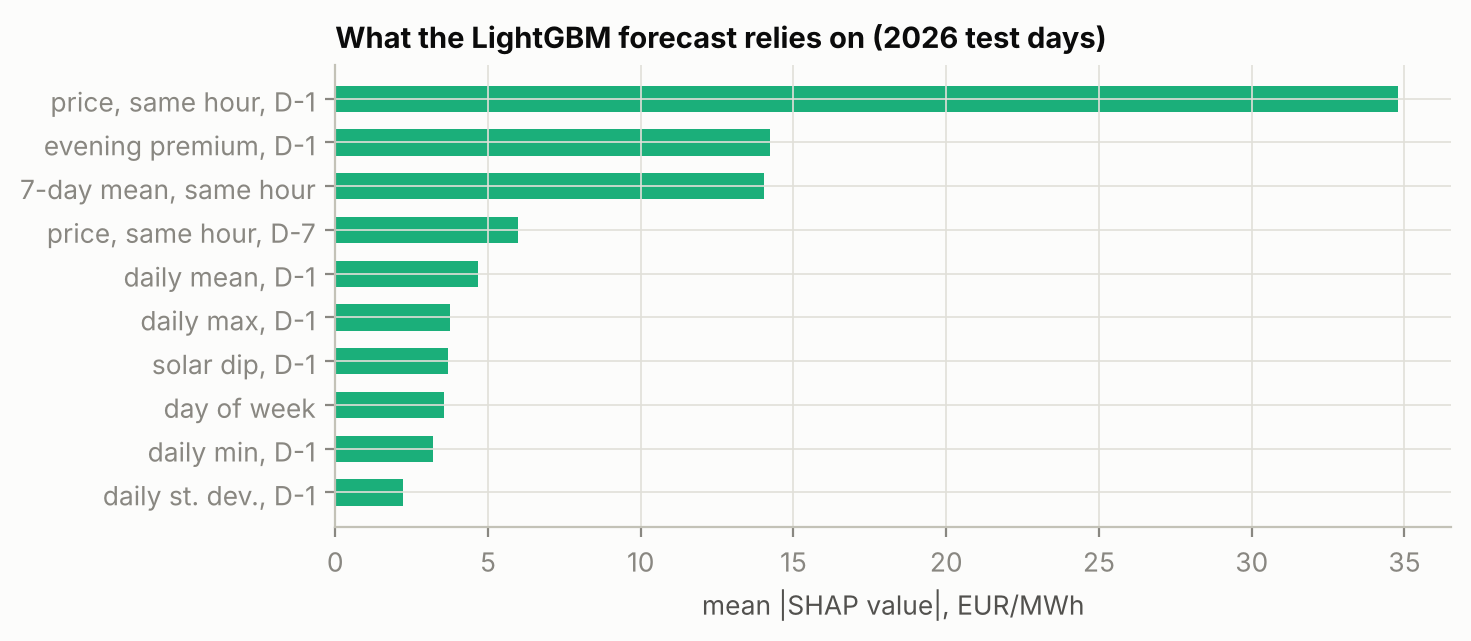

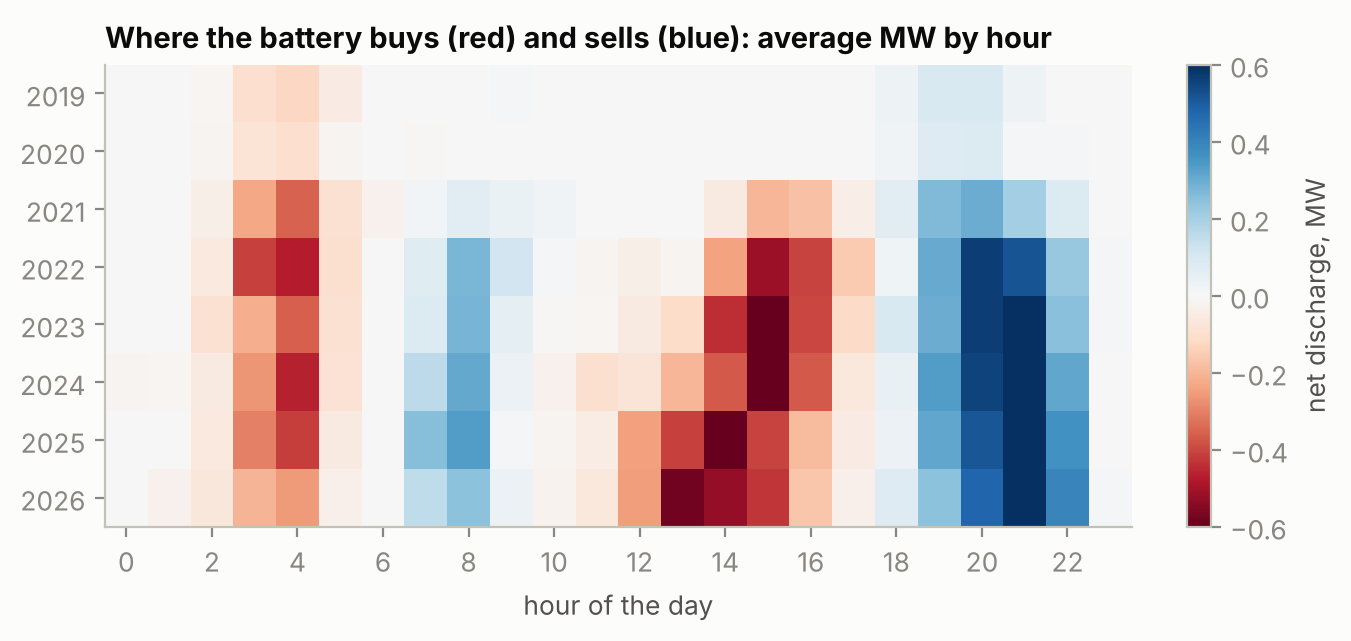

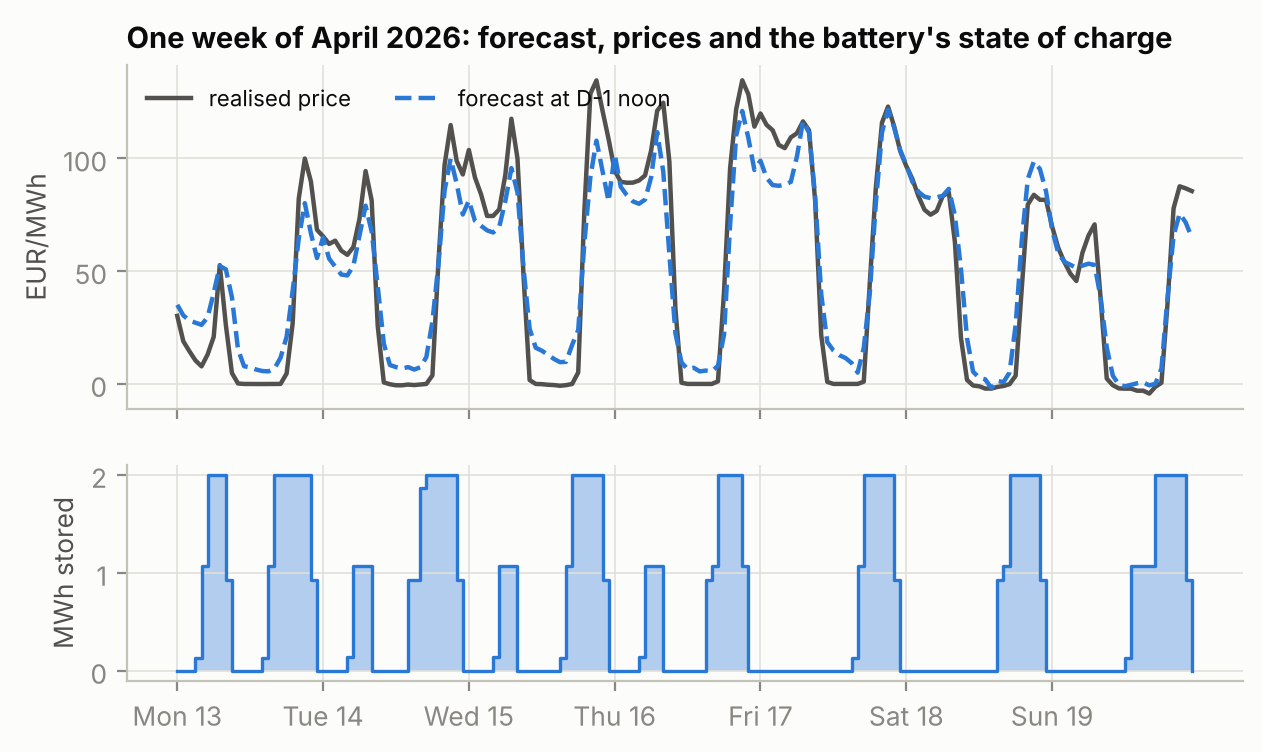

In [24]:
display(Image("results/figures/f7_shap.png", width=720)); display(Image("results/figures/f4_dispatch_heatmap.png", width=720))
display(Image("results/figures/f5_example_week.png", width=720))

### 6.8 Error analysis: where the value is lost

,0
mean_spread_error,-14.539153
share_days_underforecast,0.666667
worst10pct_share_of_loss,0.410498


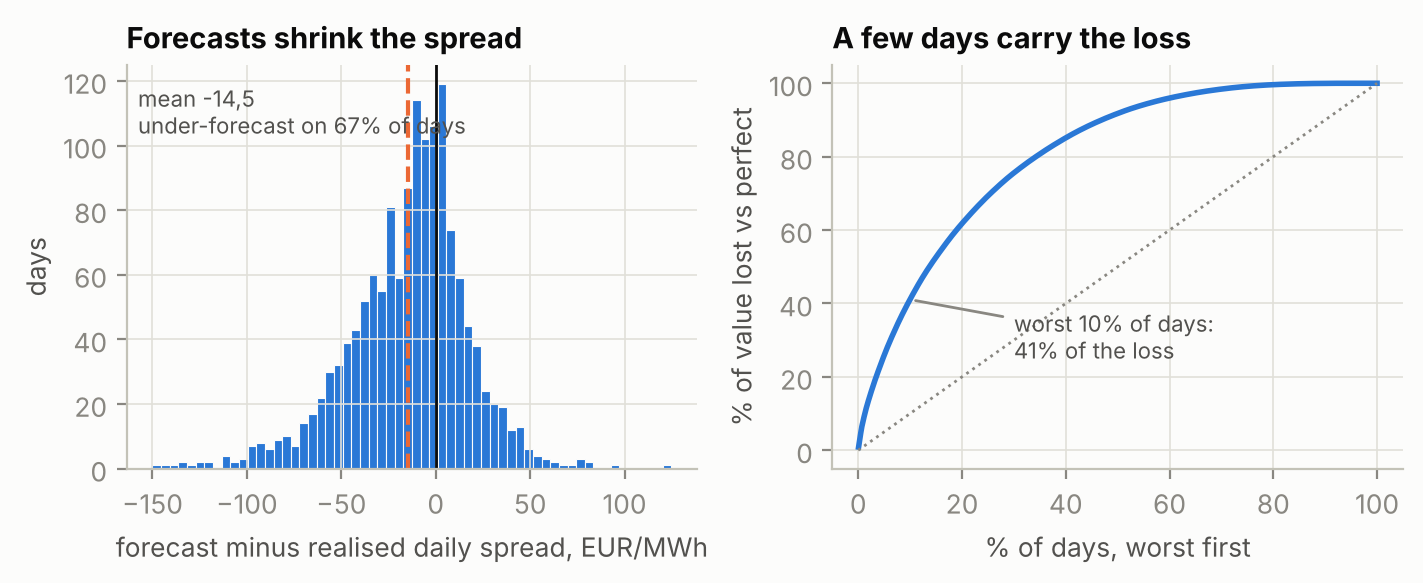

In [25]:
display(pd.read_csv("results/t10_error_analysis.csv", index_col=0)); display(Image("results/figures/f8_error_analysis.png", width=720))

### 6.9 Valuation of a 1 MW / 2 MWh merchant battery (15 years, 10% WACC, 2% fade, opex 2% of capex)

,Revenue window,Capex (EUR/kWh),Margin compression (%/yr),Year-1 revenue P50 (EUR/MW),npv_p10,npv_p50,npv_p90,prob_npv_pos,irr_p50,breakeven_capex_eur_kwh
0,2023-26,120,0.0,55103.648,88088.843,104194.633,120358.740,1.000,0.177,165.219
1,2023-26,120,3.0,55103.648,38899.022,53399.404,68123.543,1.000,0.144,143.174
2,2023-26,120,6.0,55103.648,-1137.005,12087.208,25779.784,0.879,0.111,125.246
3,2023-26,160,0.0,55103.648,-4080.884,12024.906,28189.013,0.832,0.107,165.219
4,2023-26,160,3.0,55103.648,-53270.705,-38770.323,-24046.184,0.001,0.075,143.174
5,2023-26,160,6.0,55103.648,-93306.732,-80082.519,-66389.944,0.000,0.042,125.246
6,2023-26,200,0.0,55103.648,-96250.612,-80144.821,-63980.714,0.000,0.061,165.219
7,2023-26,200,3.0,55103.648,-145440.432,-130940.050,-116215.911,0.000,0.028,143.174
8,2023-26,200,6.0,55103.648,-185476.460,-172252.246,-158559.671,0.000,-0.006,125.246
9,2023-26,280,0.0,55103.648,-280590.066,-264484.276,-248320.169,0.000,0.000,165.219


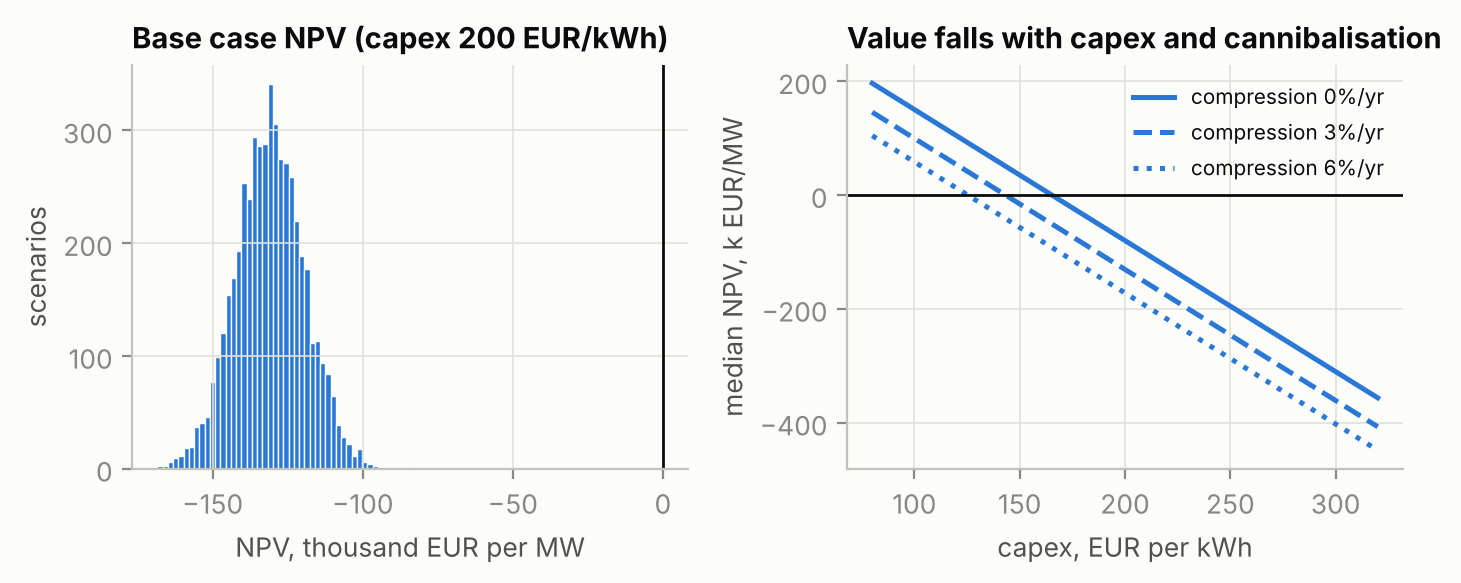

In [26]:
v = pd.read_csv("results/t8_valuation.csv")
cols = ["Revenue window", "Capex (EUR/kWh)", "Margin compression (%/yr)", "Year-1 revenue P50 (EUR/MW)",
        "npv_p10", "npv_p50", "npv_p90", "prob_npv_pos", "irr_p50", "breakeven_capex_eur_kwh"]
display(v[cols].round(3)); display(Image("results/figures/f6_valuation.png", width=720))

### 6.10 Reproducibility map
| Manuscript | File |
|---|---|
| Table 1 market facts | `results/t1_market_facts.csv` |
| Table 2 forecast accuracy | `results/t2_forecast_accuracy_test.csv`, `t2b_…validation.csv` |
| Table 3 economic results | `results/t3_…`, `t3b_…`, `t3c_test_summary.csv`, `t5_dm_tests_ensemble_vs.csv` |
| Table 4 regimes, RL, sensitivity | `results/t4_…`, `t6_…`, `t7_…` |
| Table 5 valuation | `results/t8_valuation.csv` |
| Figures 1–8 | `results/figures/f1…f8` |
| Every number quoted in the text | `results/key_numbers.json` |

**Use of generative AI.** Claude (Anthropic) was used as a coding and writing assistant; all modelling choices,
results and interpretations were checked by the author, who is responsible for them.